In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 02 · EDA — qué hay realmente en los datos de Saber 11 Antioquia

El EDA **no es hacer gráficos**: es descubrir qué decisiones hay que tomar antes de modelar. Este
notebook termina con una **tabla de decisiones**, cada una con una cifra y un motivo.
Los hallazgos y la tabla también se copian a `reports/01_eda.md`.

**Preguntas guía:** (1) unidad de análisis · (2) objetivo · (3) suciedad · (4) qué debería ser estable ·
(5) sospecha de fuga.

Especificación de esta etapa: `especificaciones/02-eda.md`.

## 0. Cargar los datos

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

from proyecto.data.load import RAW_FILENAME, load_raw_saber11

# Si data/raw/saber11_antioquia_2022.csv no existe, se descarga de datos.gov.co la primera vez.
raw = load_raw_saber11(Path.cwd().resolve().parent / "data" / "raw")
print(f"{RAW_FILENAME}: {raw.shape[0]:,} filas x {raw.shape[1]} columnas")

ID_COL = "estu_consecutivo"       # identifica al estudiante (no se muestra nunca)
GROUP_COL = "cole_cod_dane_sede"  # colegio-sede: candidato a unidad de partición
TARGET = "punt_global"

# Datos personales: la fecha de nacimiento solo se usa para calcular la edad aproximada
# al presentar la prueba (periodo 2022) y no se muestra. El identificador tampoco se muestra.
raw["edad"] = 2022 - pd.to_datetime(raw["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce").dt.year
raw = raw.drop(columns=["estu_fechanacimiento"])

saber11_antioquia_2022.csv: 144,766 filas x 51 columnas


## 1. ¿Cuál es la unidad de análisis? ¿Qué representa una fila?

*Pregunta:* ¿una fila es un estudiante? ¿Algún estudiante aparece en **varias filas**? De eso depende cómo se parte el dato.

In [3]:
print("filas:", f"{len(raw):,}", "| estudiantes distintos:", f"{raw[ID_COL].nunique():,}")
print("filas por estudiante:", raw.groupby(ID_COL).size().value_counts().to_dict())
print("filas exactamente duplicadas:", f"{raw.duplicated().sum():,}")

df = raw.drop_duplicates().reset_index(drop=True)
print(f"\nSin duplicados: {len(df):,} filas; ¿queda algún estudiante repetido? {df[ID_COL].duplicated().any()}")

filas: 144,766 | estudiantes distintos: 72,383
filas por estudiante: {2: 72383}


filas exactamente duplicadas: 72,383



Sin duplicados: 72,383 filas; ¿queda algún estudiante repetido? False


Cada estudiante aparece una sola vez, pero los estudiantes **comparten colegio**. ¿Cuántos por sede, y cuánto
del puntaje se explica solo por el colegio?

In [4]:
per_sede = df.groupby(GROUP_COL).size()
print(f"Sedes distintas: {per_sede.size:,}")
print("Estudiantes por sede:", per_sede.describe()[["min", "25%", "50%", "75%", "max"]].to_dict())
print("Sedes con menos de 10 estudiantes:", int((per_sede < 10).sum()))


def share_explained(group):
    """Proporción de la varianza del objetivo que explica el promedio de cada grupo (eta²)."""
    group_mean = df.groupby(group)[TARGET].transform("mean")
    return 1 - ((df[TARGET] - group_mean) ** 2).sum() / ((df[TARGET] - df[TARGET].mean()) ** 2).sum()


print(f"\nVarianza de {TARGET} explicada solo por la sede:      {share_explained(GROUP_COL):.1%}")
print(f"Varianza de {TARGET} explicada solo por el municipio: {share_explained('cole_cod_mcpio_ubicacion'):.1%}")

Sedes distintas: 1,447
Estudiantes por sede: {'min': 1.0, '25%': 11.5, '50%': 33.0, '75%': 69.0, 'max': 618.0}
Sedes con menos de 10 estudiantes: 319

Varianza de punt_global explicada solo por la sede:      36.0%
Varianza de punt_global explicada solo por el municipio: 11.1%


**Mi respuesta (una frase):** una fila es **un estudiante** que presentó Saber 11 en el periodo 20224 en un colegio de
Antioquia; la fuente trae cada fila **dos veces** (144.766 filas = 72.383 estudiantes) y, quitados los duplicados, ningún
estudiante se repite.

**Unidad por la que partiré los datos:** **la sede** (`cole_cod_dane_sede`), con `GroupShuffleSplit` / `GroupKFold`.
El colegio-sede explica por sí solo el **36 %** de la variación del puntaje y todos sus estudiantes comparten las variables
`cole_`. Si partiéramos por estudiante, el modelo vería compañeros del mismo colegio en entrenamiento y en prueba, aprendería
el promedio de cada colegio y el MAE saldría optimista. Partir por sede mide cómo se comporta con **colegios que nunca vio**,
que es la situación real de la app: cualquier usuario puede ingresar un colegio que no estaba en los datos.

## 2. ¿Cómo está el objetivo?

*Pregunta:* ¿qué forma tiene `punt_global`? ¿Tiene vacíos o valores fuera de la escala (0–500)?

{'count': 72383.0, 'mean': 245.9, 'std': 51.6, 'min': 100.0, '25%': 205.0, '50%': 242.0, '75%': 283.0, 'max': 477.0}
vacíos en el objetivo: 0
fuera de 0–500: 0
asimetría: 0.31


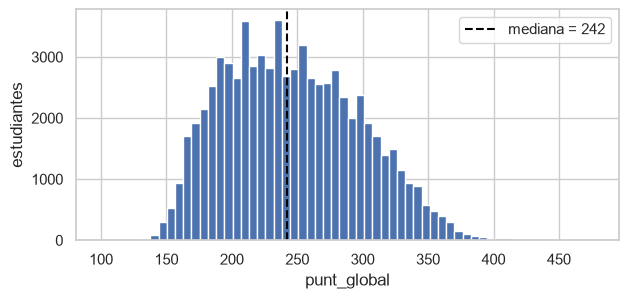

Línea base — predecir siempre la mediana: MAE = 42.8 puntos


In [5]:
print(df[TARGET].describe().round(1).to_dict())
print("vacíos en el objetivo:", df[TARGET].isna().sum())
print("fuera de 0–500:", int((~df[TARGET].between(0, 500)).sum()))
print(f"asimetría: {df[TARGET].skew():.2f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(df[TARGET], bins=60, color="#4c72b0")
ax.axvline(df[TARGET].median(), color="black", ls="--", label=f"mediana = {df[TARGET].median():.0f}")
ax.set_xlabel(TARGET); ax.set_ylabel("estudiantes"); ax.legend()
plt.show()

median_mae = (df[TARGET] - df[TARGET].median()).abs().mean()
print(f"Línea base — predecir siempre la mediana: MAE = {median_mae:.1f} puntos")

**Hallazgo:** `punt_global` va de 100 a 477 puntos (mediana 242, promedio 245,9), sin vacíos ni valores fuera de la
escala. La distribución es casi simétrica (asimetría 0,31), con una cola leve hacia puntajes altos: no hace falta
transformar el objetivo.

**Línea base (qué resultado obtiene una regla trivial):** predecir siempre la mediana da un **MAE de 42,8 puntos**
(coincide con el notebook 01).

## 3. ¿Qué tan sucios están los datos y de qué manera?

*Preguntas:* ¿hay números guardados como texto? ¿valores centinela? ¿valores imposibles? ¿vacíos? ¿duplicados?
¿datos personales? (guía, secciones 3.1 a 3.9).

In [6]:
print(df.dtypes.astype(str).value_counts().to_dict())
print("\nvacíos por columna (mayores):")
print(df.isna().mean().sort_values(ascending=False).head(12).round(3))
print("\nColumnas con un solo valor (no aportan):", [c for c in df.columns if df[c].nunique(dropna=False) == 1])

{'str': 34, 'int64': 15, 'float64': 1, 'int32': 1}

vacíos por columna (mayores):
cole_bilingue           0.164
fami_estratovivienda    0.065
fami_educacionpadre     0.059
fami_tieneinternet      0.059
fami_educacionmadre     0.058
fami_tieneautomovil     0.050
fami_tienelavadora      0.047
fami_tienecomputador    0.047
fami_cuartoshogar       0.047
fami_personashogar      0.046
cole_caracter           0.033
desemp_ingles           0.001
dtype: float64

Columnas con un solo valor (no aportan): ['periodo', 'cole_cod_depto_ubicacion', 'cole_depto_ubicacion', 'estu_estudiante']


### 3.1–3.2 Números como texto y valores centinela

Varias variables de familia son categorías **ordenadas** guardadas como texto, y algunas tienen respuestas que funcionan
como "dato no disponible".

In [7]:
for col in ["fami_estratovivienda", "fami_personashogar", "fami_cuartoshogar"]:
    print(f"{col:22s}", sorted(df[col].dropna().unique()))

sentinels = {"fami_educacionmadre": ["No sabe", "No Aplica"],
             "fami_educacionpadre": ["No sabe", "No Aplica"],
             "fami_estratovivienda": ["Sin Estrato"]}
print()
for col, values in sentinels.items():
    counts = {v: int((df[col] == v).sum()) for v in values}
    print(f"{col:22s} {counts}  vacíos reales: {df[col].isna().sum():,}")

fami_estratovivienda   ['Estrato 1', 'Estrato 2', 'Estrato 3', 'Estrato 4', 'Estrato 5', 'Estrato 6', 'Sin Estrato']
fami_personashogar     ['1 a 2', '3 a 4', '5 a 6', '7 a 8', '9 o más']
fami_cuartoshogar      ['Cinco', 'Cuatro', 'Dos', 'Seis o mas', 'Tres', 'Uno']



fami_educacionmadre    {'No sabe': 1695, 'No Aplica': 156}  vacíos reales: 4,196


fami_educacionpadre    {'No sabe': 5966, 'No Aplica': 1255}  vacíos reales: 4,267
fami_estratovivienda   {'Sin Estrato': 1561}  vacíos reales: 4,722


### 3.3 Valores imposibles: edad al presentar la prueba

In [8]:
print("Percentiles de edad:", df["edad"].quantile([0, 0.001, 0.01, 0.5, 0.99, 0.999, 1]).to_dict())
print("Edades menores de 13:", df["edad"].lt(13).sum(), "->", df.loc[df["edad"].lt(13), "edad"].value_counts().sort_index().to_dict())
print("Edades entre 25 y 60:", df["edad"].between(26, 60).sum(), "| mayores de 60:", df["edad"].gt(60).sum())

Percentiles de edad: {0.0: 0.0, 0.001: 15.0, 0.01: 16.0, 0.5: 17.0, 0.99: 36.0, 0.999: 56.0, 1.0: 80.0}
Edades menores de 13: 30 -> {0: 3, 4: 1, 6: 1, 7: 1, 8: 1, 9: 2, 10: 11, 11: 5, 12: 5}
Edades entre 25 y 60: 1807 | mayores de 60: 28


**Hallazgo:** la mediana es 17 años. Hay **30 estudiantes con menos de 13 años** (incluso 0 años): es imposible
presentar Saber 11 a esa edad, son fechas mal registradas. En cambio, los mayores de 25 (1.807 entre 26 y 60 años, 28 mayores
de 60) son plausibles: adultos que validan el bachillerato. *La edad es aproximada (año de la prueba − año de nacimiento).*

### 3.5 Vacíos que significan algo

¿Los estudiantes con vacíos tienen el mismo puntaje que los demás? Si no, el vacío **es información**.

In [9]:
fami_cols = [c for c in df.columns if c.startswith("fami_")]
rows = []
for col in fami_cols + ["cole_bilingue", "cole_caracter"]:
    missing = df[col].isna()
    rows.append({"columna": col, "% vacío": missing.mean(),
                 "puntaje con vacío": df.loc[missing, TARGET].mean(),
                 "puntaje sin vacío": df.loc[~missing, TARGET].mean()})
pd.DataFrame(rows).set_index("columna").style.format({"% vacío": "{:.1%}", "puntaje con vacío": "{:.1f}", "puntaje sin vacío": "{:.1f}"})

,% vacío,puntaje con vacío,puntaje sin vacío
columna,,,
fami_cuartoshogar,4.7%,234.4,246.5
fami_educacionmadre,5.8%,225.9,247.1
fami_educacionpadre,5.9%,226.0,247.1
fami_estratovivienda,6.5%,227.1,247.2
fami_personashogar,4.6%,234.2,246.5
fami_tieneautomovil,5.0%,230.7,246.7
fami_tienecomputador,4.7%,232.5,246.6
fami_tieneinternet,5.9%,225.9,247.1
fami_tienelavadora,4.7%,232.2,246.6


In [10]:
print("Estudiantes sin NINGUNA respuesta fami_:", int(df[fami_cols].isna().all(axis=1).sum()))
print("Estudiantes con al menos un vacío fami_:", f"{df[fami_cols].isna().any(axis=1).mean():.1%}")

Estudiantes sin NINGUNA respuesta fami_: 1790
Estudiantes con al menos un vacío fami_: 10.1%


**Hallazgos de calidad (con cifras):**

- **Duplicados:** 72.383 filas exactamente duplicadas (50 % del archivo).
- **Texto ordenado:** estrato ("Estrato 1"…"Estrato 6"), personas en el hogar ("1 a 2"…"9 o más") y cuartos ("Uno"…"Seis
  o mas") son categorías con orden natural guardadas como texto.
- **Centinelas:** "No sabe" (1.695 madre, 5.966 padre), "No Aplica" (156 madre, 1.255 padre), "Sin Estrato" (1.561).
- **Vacíos no aleatorios:** el 10,1 % de los estudiantes tiene algún vacío en `fami_`, y quienes los tienen sacan en
  promedio **~18 puntos menos** (229,2 vs. 247,8). En `cole_bilingue` (16,4 % vacío) la diferencia es de 16 puntos. El
  vacío no es ruido: es información.
- **Edades imposibles:** 30 estudiantes con menos de 13 años.
- **Columnas constantes:** `periodo`, `cole_cod_depto_ubicacion`, `cole_depto_ubicacion`, `estu_estudiante` tienen un
  solo valor.

## 4. ¿Qué variables deberían ser estables y no lo son?

Cada estudiante aparece una sola vez, así que la constancia se revisa **por colegio-sede**: los datos del colegio
deberían ser iguales para todos sus estudiantes.

In [11]:
stable_candidates = ["cole_mcpio_ubicacion", "cole_area_ubicacion", "cole_naturaleza", "cole_calendario",
                     "cole_caracter", "cole_bilingue", "cole_genero", "cole_jornada"]
changes = {c: df.groupby(GROUP_COL)[c].nunique().gt(1).mean() for c in stable_candidates}
print(pd.Series(changes, name="% de sedes con más de un valor").round(3))

cole_mcpio_ubicacion    0.000
cole_area_ubicacion     0.000
cole_naturaleza         0.000
cole_calendario         0.000
cole_caracter           0.000
cole_bilingue           0.000
cole_genero             0.000
cole_jornada            0.207
Name: % de sedes con más de un valor, dtype: float64


**Hallazgo:** todas las características del colegio son **constantes dentro de cada sede (0 %)**, excepto
`cole_jornada`, que tiene más de un valor en el **20,7 %** de las sedes.

**¿Ruido o cambio real? ¿Por qué?** Cambio **real**: una misma sede puede tener jornada mañana, tarde y sabatina. La
jornada es del estudiante dentro de la sede, no un error.

## 5. ¿Hay algo que suene a fuga de información?

*Pregunta:* ¿alguna columna contiene la respuesta, o solo se conoce **después** del examen?

In [12]:
score_cols = ["punt_matematicas", "punt_lectura_critica", "punt_sociales_ciudadanas", "punt_c_naturales", "punt_ingles"]
print("Correlación con punt_global:")
print(df[score_cols].corrwith(df[TARGET]).round(3))
print("\nPuntaje promedio por desemp_ingles:", df.groupby("desemp_ingles")[TARGET].mean().round(1).to_dict())
print("\nestu_estadoinvestigacion:")
print(df.groupby("estu_estadoinvestigacion")[TARGET].agg(["size", "mean"]).round(1))

Correlación con punt_global:
punt_matematicas            0.904
punt_lectura_critica        0.908
punt_sociales_ciudadanas    0.915
punt_c_naturales            0.916
punt_ingles                 0.798
dtype: float64

Puntaje promedio por desemp_ingles: {'A-': 211.8, 'A1': 257.9, 'A2': 289.6, 'B+': 347.6, 'B1': 317.7}

estu_estadoinvestigacion:
                           size   mean
estu_estadoinvestigacion              
PUBLICAR                  72357  245.9
VALIDEZ OFICINA JURÍDICA     26  250.5


**Columnas sospechosas de fuga y por qué:**

- `punt_matematicas`, `punt_lectura_critica`, `punt_sociales_ciudadanas`, `punt_c_naturales`, `punt_ingles`: correlación
  de **0,80 a 0,92** con el objetivo. El puntaje global se calcula con ellas: **son la respuesta**.
- `desemp_ingles`: el puntaje promedio sube de 211,8 (A-) a 347,6 (B+). Sale del resultado de inglés.
- `estu_estadoinvestigacion`: solo 26 estudiantes en revisión jurídica. No predice casi nada, pero se conoce **después**
  del examen, así que no puede ser una entrada del modelo.

Las siete se excluyen (decisión ya tomada en el caso de negocio).

## 6. Categorías raras, alta cardinalidad y calendario

*Guía, sección 3.8.*

In [13]:
for col in ["estu_nacionalidad", "estu_pais_reside", "estu_tipodocumento", "estu_privado_libertad", "estu_depto_reside"]:
    share = df[col].value_counts(normalize=True)
    print(f"{col:24s} más frecuente: {share.index[0]} ({share.iloc[0]:.1%}) · categorías con < 1 %: {(share < 0.01).sum()}")

print("\nValores distintos:", df[["cole_mcpio_ubicacion", "estu_mcpio_reside", "cole_nombre_sede", GROUP_COL]].nunique().to_dict())
print("Nombres de sede que corresponden a más de un código:",
      int(df.groupby("cole_nombre_sede")[GROUP_COL].nunique().gt(1).sum()))
print("\nCalendario:")
print(df.groupby("cole_calendario")[TARGET].agg(["size", "mean"]).round(1))
print("Sedes con calendario OTRO:", df.loc[df.cole_calendario == "OTRO", GROUP_COL].nunique())

estu_nacionalidad        más frecuente: COLOMBIA (98.5%) · categorías con < 1 %: 23
estu_pais_reside         más frecuente: COLOMBIA (98.5%) · categorías con < 1 %: 23
estu_tipodocumento       más frecuente: TI (81.5%) · categorías con < 1 %: 7
estu_privado_libertad    más frecuente: N (99.8%) · categorías con < 1 %: 1
estu_depto_reside        más frecuente: ANTIOQUIA (99.8%) · categorías con < 1 %: 19

Valores distintos: {'cole_mcpio_ubicacion': 125, 'estu_mcpio_reside': 173, 'cole_nombre_sede': 1396, 'cole_cod_dane_sede': 1447}
Nombres de sede que corresponden a más de un código: 30

Calendario:
                  size   mean
cole_calendario              
A                72148  246.0
OTRO               235  227.1
Sedes con calendario OTRO: 3


**Hallazgo:**

- `estu_nacionalidad`, `estu_pais_reside` y `estu_depto_reside` son casi constantes (98,5 % o más en un solo valor), con
  23 categorías de menos del 1 %.
- Municipios (125 de colegio, 173 de residencia) y sedes (1.447) tienen **alta cardinalidad**. El nombre de la sede no
  identifica de forma única (30 nombres se repiten en varios códigos): ningún identificador del colegio se usa como predictor (decisión 9).
- **Calendario "OTRO": 235 estudiantes en 3 sedes** (0,3 %), con un puntaje promedio de 227,1, frente a 246,0 en
  calendario A. **Se excluyen:** con tan pocos casos el modelo no puede aprender nada confiable de esa categoría. En los
  datos no hay calendario B, así que **el modelo aplica a estudiantes de calendario A**.

## 7. Un vistazo a la señal

¿Qué variables de colegio, estudiante y familia parecen relacionarse con el puntaje?

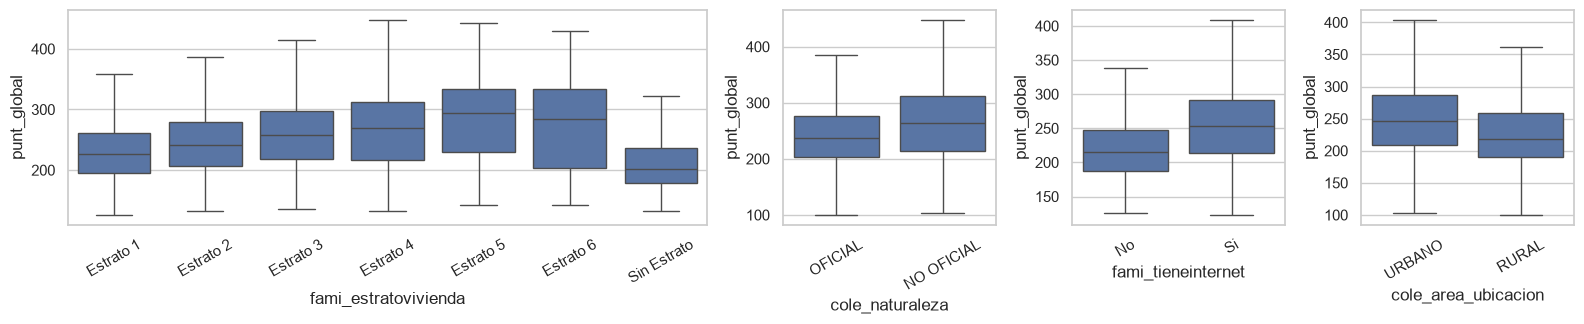

In [14]:
view = [("fami_estratovivienda", ["Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6", "Sin Estrato"]),
        ("cole_naturaleza", None), ("fami_tieneinternet", None), ("cole_area_ubicacion", None)]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), gridspec_kw={"width_ratios": [3, 1, 1, 1]})
for ax, (col, order) in zip(axes, view):
    sns.boxplot(data=df, x=col, y=TARGET, order=order, ax=ax, color="#4c72b0", showfliers=False)
    ax.set_xlabel(col); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Hallazgo:** el puntaje sube con el estrato (de ~231 en estrato 1 a ~281 en estrato 5) y es más alto en colegios no
oficiales, en hogares con internet y en zona urbana. Hay señal en las variables `cole_` y `fami_`, pero también **riesgo de
equidad**: estas mismas variables describen grupos en desventaja (se revisará el error por segmento en la validación).

## 8. Tabla de decisiones (entregable del EDA)

Cada decisión con **cifra → acción → motivo**. Se copia a `reports/01_eda.md`. Todas fueron aprobadas por el grupo el 31 oct 2026, sin cambios; se aplican en `03_preprocesamiento.ipynb`.

| # | Hallazgo (con cifra) | Decisión | Motivo |
|---|---|---|---|
| 1 | 72.383 filas exactamente duplicadas (50 % del archivo) | Eliminar duplicados exactos al cargar | Un mismo estudiante en entrenamiento y prueba haría que la métrica saliera optimista |
| 2 | 5 puntajes por área con correlación de 0,80–0,92 con el objetivo; `desemp_ingles` y `estu_estadoinvestigacion` se conocen después del examen | Excluir las 7 columnas | Son la respuesta o información posterior: fuga |
| 3 | `estu_consecutivo` identifica al estudiante; `estu_fechanacimiento` es dato personal | Usar `estu_consecutivo` solo para controlar duplicados (nunca como variable); convertir la fecha de nacimiento en edad y eliminarla | No exponer datos personales; la edad conserva la información útil |
| 4 | 30 estudiantes con edad menor de 13 años | Edad < 13 → vacío (sin borrar la fila) | Es imposible presentar Saber 11 a esa edad; borrar filas perdería el resto de su información |
| 5 | 10,1 % con algún vacío en `fami_`, con ~18 puntos menos de promedio; `cole_bilingue` 16,4 % vacío, 16 puntos menos | Imputar vacíos como categoría propia "sin respuesta" dentro del `Pipeline` | El vacío es información, no ruido: imputar con la moda la borraría |
| 6 | Centinelas: "No sabe" (1.695 / 5.966), "No Aplica" (156 / 1.255), "Sin Estrato" (1.561, puntaje 211,2) | Mantenerlos como categorías propias (no convertir a vacío) | Tienen puntajes distintos al resto: llevan información |
| 7 | Estrato, personas y cuartos del hogar son categorías ordenadas guardadas como texto | Convertirlas a números ordenados (estrato 1–6, personas, cuartos) | Conservar el orden ayuda al modelo y simplifica la app |
| 8 | 4 columnas con un solo valor (`periodo`, `cole_cod_depto_ubicacion`, `cole_depto_ubicacion`, `estu_estudiante`) | Eliminarlas | No aportan información |
| 9 | Las columnas que identifican al colegio (`cole_cod_dane_sede`, `cole_cod_dane_establecimiento`, `cole_codigo_icfes`, `cole_nombre_establecimiento`, `cole_nombre_sede`) tienen 1.071 a 1.807 valores distintos; 30 nombres de sede se repiten en varios códigos | Excluirlas como predictores. `cole_cod_dane_sede` se conserva **solo para agrupar** al partir (decisión 10). Se mantienen los atributos del colegio: naturaleza, jornada, calendario, zona, bilingüe, carácter, género y municipio | En prueba aparecerían colegios nunca vistos, y en entrenamiento el modelo memorizaría el promedio de cada colegio en vez de aprender de sus características; los atributos sí los puede ingresar el usuario de la app para cualquier colegio |
| 10 | La sede explica el 36 % de la variación del puntaje; 1.447 sedes | Partir entrenamiento/prueba y validación cruzada **por sede** (`cole_cod_dane_sede`, `GroupShuffleSplit` / `GroupKFold`) | Mide el error con colegios que el modelo nunca vio, como en la app; partir por estudiante daría un MAE optimista |
| 11 | 235 estudiantes (0,3 %) de calendario "OTRO" en 3 sedes; no hay calendario B | Excluirlos. Alcance: el modelo aplica a estudiantes de **calendario A** | Muy pocos casos para aprender algo confiable; simplifica el modelo y el formulario de la app |

## Entregable de esta etapa

- [x] Este notebook ejecuta de principio a fin.
- [x] La tabla de decisiones tiene **al menos 5** filas con cifra y motivo.
- [ ] `reports/01_eda.md` está actualizado.
- [x] Declaré mi **unidad de análisis** por escrito (unidad: estudiante; partición: por sede).

**Siguiente:** `03_preprocesamiento.ipynb`.